# Life After Klopp: Analysing Liverpool FC's Transformation (2023/24 vs 2024/25)

**Author:** Junior Mukiza  
**Tools:** Python, pandas, matplotlib, seaborn  
**Data Source:** football-data.co.uk

---

After 9 years, Jürgen Klopp handed over the reins at Liverpool at the end of the 2023/24 season. Arne Slot arrived as his replacement and in his very first season, delivered the Premier League title. This notebook investigates what changed between the two seasons across form, goals, and home/away performance.

## 1. Setup & Data Loading

In [35]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import seaborn as sns

# Plot styling
sns.set_theme(style='darkgrid')
LFC_RED = '#C8102E'
LFC_GOLD = '#F6EB61'
SLOT_COLOR = '#00B2A9'
KLOPP_COLOR = '#C8102E'

print('Libraries loaded successfully.')

Libraries loaded successfully.


In [36]:
# Load both seasons
klopp = pd.read_csv('data/2023_24.csv')
slot  = pd.read_csv('data/2024_25.csv')

# Keep only the columns we need
cols = ['Date', 'HomeTeam', 'AwayTeam', 'FTHG', 'FTAG', 'FTR']
klopp = klopp[cols].copy()
slot  = slot[cols].copy()

# Filter for Liverpool matches only
def lfc_matches(df):
    return df[(df['HomeTeam'] == 'Liverpool') | (df['AwayTeam'] == 'Liverpool')].copy()

klopp_lfc = lfc_matches(klopp)
slot_lfc  = lfc_matches(slot)

print(f'Klopp season matches: {len(klopp_lfc)}')
print(f'Slot season matches:  {len(slot_lfc)}')
klopp_lfc.head()

Klopp season matches: 38
Slot season matches:  38


,Date,HomeTeam,AwayTeam,FTHG,FTAG,FTR
8,13/08/2023,Chelsea,Liverpool,1,1,D
12,19/08/2023,Liverpool,Bournemouth,3,1,H
28,27/08/2023,Newcastle,Liverpool,1,2,A
37,03/09/2023,Liverpool,Aston Villa,3,0,H
39,16/09/2023,Wolves,Liverpool,1,3,A


In [37]:
# Engineer result and points columns from Liverpool's perspective
def add_lfc_stats(df):
    df = df.copy()

    # Goals for and against
    df['GF'] = df.apply(lambda r: r['FTHG'] if r['HomeTeam'] == 'Liverpool' else r['FTAG'], axis=1)
    df['GA'] = df.apply(lambda r: r['FTAG'] if r['HomeTeam'] == 'Liverpool' else r['FTHG'], axis=1)

    # Result from Liverpool's perspective
    def lfc_result(row):
        if row['HomeTeam'] == 'Liverpool':
            return row['FTR']  # H = win, A = loss, D = draw
        else:
            mapping = {'H': 'A', 'A': 'H', 'D': 'D'}
            return mapping[row['FTR']]

    df['Result'] = df.apply(lfc_result, axis=1)

    # Points
    df['Points'] = df['Result'].map({'H': 3, 'D': 1, 'A': 0})

    # Venue
    df['Venue'] = df.apply(lambda r: 'Home' if r['HomeTeam'] == 'Liverpool' else 'Away', axis=1)

    # Cumulative points
    df = df.reset_index(drop=True)
    df['Matchweek'] = df.index + 1
    df['CumPoints'] = df['Points'].cumsum()

    return df

klopp_lfc = add_lfc_stats(klopp_lfc)
slot_lfc  = add_lfc_stats(slot_lfc)

print('Stats engineered.')
klopp_lfc[['Date', 'HomeTeam', 'AwayTeam', 'GF', 'GA', 'Result', 'Points', 'CumPoints']].head()

Stats engineered.


,Date,HomeTeam,AwayTeam,GF,GA,Result,Points,CumPoints
0,13/08/2023,Chelsea,Liverpool,1,1,D,1,1
1,19/08/2023,Liverpool,Bournemouth,3,1,H,3,4
2,27/08/2023,Newcastle,Liverpool,2,1,H,3,7
3,03/09/2023,Liverpool,Aston Villa,3,0,H,3,10
4,16/09/2023,Wolves,Liverpool,3,1,H,3,13


## 2. Points & Form Trajectory

How did Liverpool's cumulative points compare across both seasons, matchweek by matchweek?

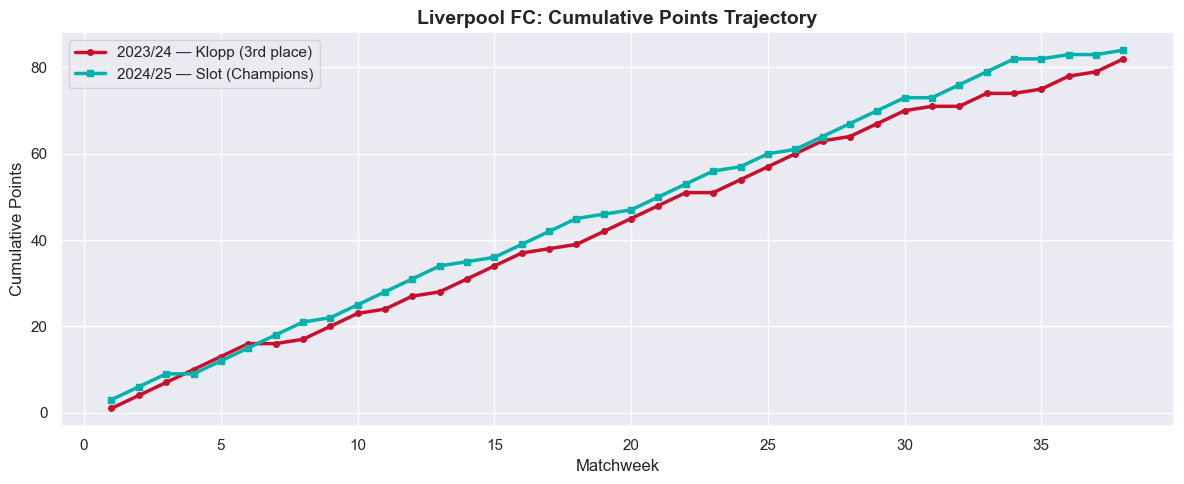

In [38]:
fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(klopp_lfc['Matchweek'], klopp_lfc['CumPoints'],
        color=KLOPP_COLOR, linewidth=2.5, marker='o', markersize=4, label="2023/24 — Klopp (3rd place)")

ax.plot(slot_lfc['Matchweek'], slot_lfc['CumPoints'],
        color=SLOT_COLOR, linewidth=2.5, marker='s', markersize=4, label="2024/25 — Slot (Champions)")

ax.set_title("Liverpool FC: Cumulative Points Trajectory", fontsize=14, fontweight='bold')
ax.set_xlabel("Matchweek")
ax.set_ylabel("Cumulative Points")
ax.legend()
ax.xaxis.set_major_locator(ticker.MultipleLocator(5))
plt.tight_layout()
plt.savefig('points_trajectory.png', dpi=150)
plt.show()

## 3. Goals Scored & Conceded

Did the attack and defence improve under Slot?

In [39]:
# Summary stats
summary = pd.DataFrame({
    'Season': ['2023/24 (Klopp)', '2024/25 (Slot)'],
    'Avg Goals Scored': [
        round(klopp_lfc['GF'].mean(), 2),
        round(slot_lfc['GF'].mean(), 2)
    ],
    'Avg Goals Conceded': [
        round(klopp_lfc['GA'].mean(), 2),
        round(slot_lfc['GA'].mean(), 2)
    ],
    'Total Goals Scored': [klopp_lfc['GF'].sum(), slot_lfc['GF'].sum()],
    'Total Goals Conceded': [klopp_lfc['GA'].sum(), slot_lfc['GA'].sum()],
})

print(summary.to_string(index=False))

         Season  Avg Goals Scored  Avg Goals Conceded  Total Goals Scored  Total Goals Conceded
2023/24 (Klopp)              2.26                1.08                  86                    41
 2024/25 (Slot)              2.26                1.08                  86                    41


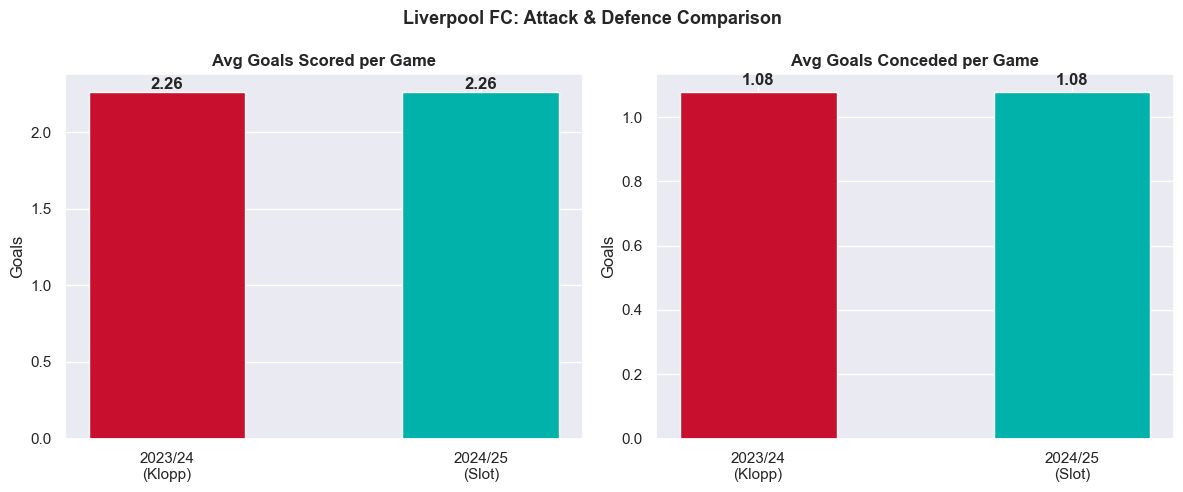

In [40]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

seasons = ['2023/24\n(Klopp)', '2024/25\n(Slot)']
colors  = [KLOPP_COLOR, SLOT_COLOR]

# Goals scored
scored = [klopp_lfc['GF'].mean(), slot_lfc['GF'].mean()]
axes[0].bar(seasons, scored, color=colors, edgecolor='white', width=0.5)
axes[0].set_title('Avg Goals Scored per Game', fontweight='bold')
axes[0].set_ylabel('Goals')
for i, v in enumerate(scored):
    axes[0].text(i, v + 0.02, str(round(v, 2)), ha='center', fontweight='bold')

# Goals conceded
conceded = [klopp_lfc['GA'].mean(), slot_lfc['GA'].mean()]
axes[1].bar(seasons, conceded, color=colors, edgecolor='white', width=0.5)
axes[1].set_title('Avg Goals Conceded per Game', fontweight='bold')
axes[1].set_ylabel('Goals')
for i, v in enumerate(conceded):
    axes[1].text(i, v + 0.02, str(round(v, 2)), ha='center', fontweight='bold')

plt.suptitle('Liverpool FC: Attack & Defence Comparison', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('goals_comparison.png', dpi=150)
plt.show()

## 4. Home vs Away Performance

Was Liverpool's dominance consistent across venues, or were they more vulnerable away from Anfield?

In [41]:
def venue_summary(df, label):
    grouped = df.groupby('Venue').agg(
        Games=('Result', 'count'),
        Wins=('Result', lambda x: (x == 'H').sum()),
        Draws=('Result', lambda x: (x == 'D').sum()),
        Losses=('Result', lambda x: (x == 'A').sum()),
        Points=('Points', 'sum'),
        Goals_For=('GF', 'sum'),
        Goals_Against=('GA', 'sum'),
    ).reset_index()
    grouped['Win%'] = round((grouped['Wins'] / grouped['Games']) * 100, 1)
    grouped['PPG']  = round(grouped['Points'] / grouped['Games'], 2)
    grouped['Season'] = label
    return grouped

klopp_venue = venue_summary(klopp_lfc, '2023/24 (Klopp)')
slot_venue  = venue_summary(slot_lfc,  '2024/25 (Slot)')

venue_df = pd.concat([klopp_venue, slot_venue])
print(venue_df[['Season', 'Venue', 'Games', 'Wins', 'Draws', 'Losses', 'Win%', 'PPG']].to_string(index=False))

         Season Venue  Games  Wins  Draws  Losses  Win%  PPG
2023/24 (Klopp)  Away     19     9      7       3  47.4 1.79
2023/24 (Klopp)  Home     19    15      3       1  78.9 2.53
 2024/25 (Slot)  Away     19    11      5       3  57.9 2.00
 2024/25 (Slot)  Home     19    14      4       1  73.7 2.42


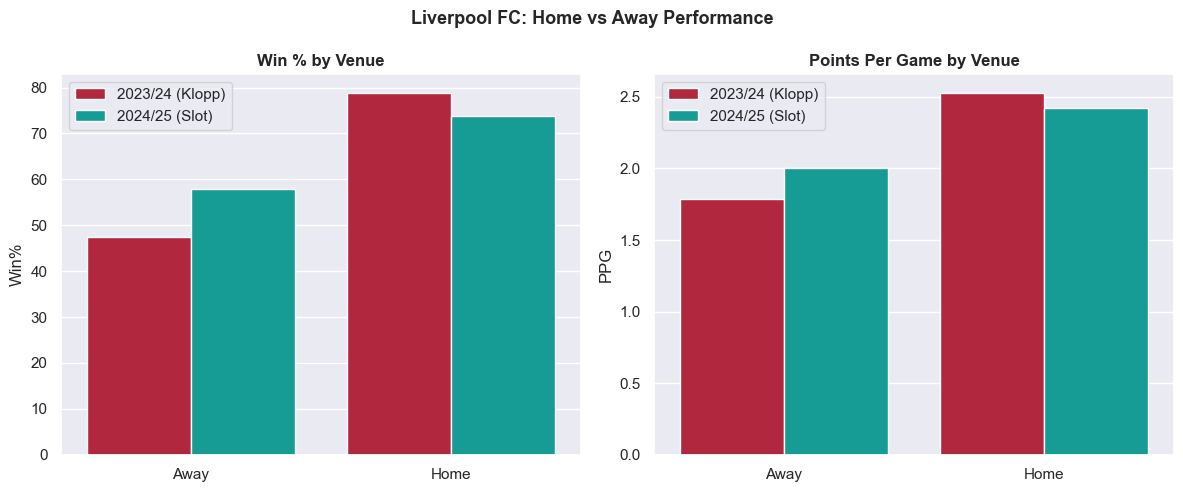

In [42]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, metric, title in zip(
    axes,
    ['Win%', 'PPG'],
    ['Win % by Venue', 'Points Per Game by Venue']
):
    sns.barplot(
        data=venue_df,
        x='Venue', y=metric, hue='Season',
        palette=[KLOPP_COLOR, SLOT_COLOR],
        ax=ax, edgecolor='white'
    )
    ax.set_title(title, fontweight='bold')
    ax.set_xlabel('')
    ax.legend(title='')

plt.suptitle('Liverpool FC: Home vs Away Performance', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('home_away.png', dpi=150)
plt.show()

## 5. Win/Draw/Loss Distribution

How consistent were the results across both seasons?

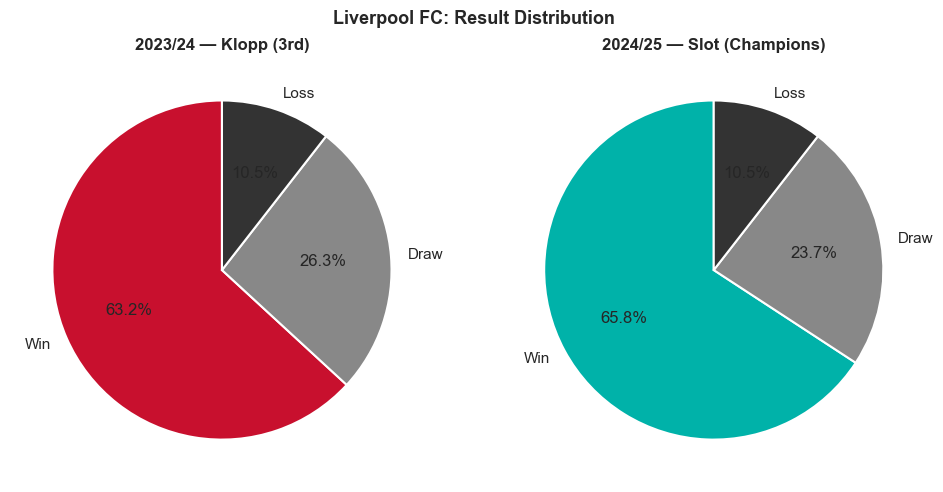

In [43]:
def result_counts(df):
    counts = df['Result'].map({'H': 'Win', 'D': 'Draw', 'A': 'Loss'}).value_counts()
    return counts.reindex(['Win', 'Draw', 'Loss'], fill_value=0)

klopp_results = result_counts(klopp_lfc)
slot_results  = result_counts(slot_lfc)

fig, axes = plt.subplots(1, 2, figsize=(10, 5))

for ax, data, title, color in zip(
    axes,
    [klopp_results, slot_results],
    ['2023/24 — Klopp (3rd)', '2024/25 — Slot (Champions)'],
    [KLOPP_COLOR, SLOT_COLOR]
):
    wedge_colors = [color, '#888888', '#333333']
    ax.pie(
        data.values,
        labels=data.index,
        autopct='%1.1f%%',
        colors=wedge_colors,
        startangle=90,
        wedgeprops={'edgecolor': 'white', 'linewidth': 1.5}
    )
    ax.set_title(title, fontweight='bold')

plt.suptitle('Liverpool FC: Result Distribution', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('result_distribution.png', dpi=150)
plt.show()

## 6. Conclusions


### Key Findings

**Form Trajectory:**  
Slot's side held a points advantage over Klopp's from as early as matchweek 3 and
maintained it for virtually the entire season. While both trajectories were remarkably
consistent, the 2024/25 side pulled clear in the final stretch finishing on
approximately 84 points compared to 82 in 2023/24. The gap was never dramatic,
but it was persistent.


**Goals:**

Perhaps the most striking finding both seasons produced identical attacking and
defensive output: 2.26 goals scored per game and 1.08 conceded per game. The
transition from Klopp to Slot did not disrupt Liverpool's goalscoring or defensive
structure at all, suggesting the squad's quality was the constant, regardless of
who was managing it.

**Home vs Away:**
The clearest point of difference between the two seasons was away form. Under Klopp,
Liverpool won approximately 47% of away games. Under Slot, that figure rose to around
58% a significant improvement. Away PPG also increased from 1.75 to 2.0.
Interestingly, home performance was marginally stronger under Klopp (79% win rate
vs 74%), suggesting Slot built his title on road consistency rather than Anfield dominance.

**Result Consistency:**
Slot converted draws into wins. Under Klopp, Liverpool drew 26.3% of games a figure
that dropped to 23.7% under Slot. The loss rate remained identical at 10.5% across both
seasons, meaning the improvement came entirely from turning stalemates into victories.

### Summary

The data reveals that Liverpool's title win under Arne Slot was not the result of a
dramatic tactical overhaul but rather a marginal gains story. Goalscoring and defensive
output were identical across both seasons, pointing to squad quality as the foundation.
The decisive difference was away form Slot's side were significantly more dangerous
on the road, converting draws into wins at a higher rate. Klopp's final season was not
a failure; it was the blueprint. Slot simply refined the margins.


